In [ ]:

!pip install openmeteo-requests
!pip install requests-cache retry-requests numpy pandas
!pip install rasterio


get distribution of points that correspond to population density

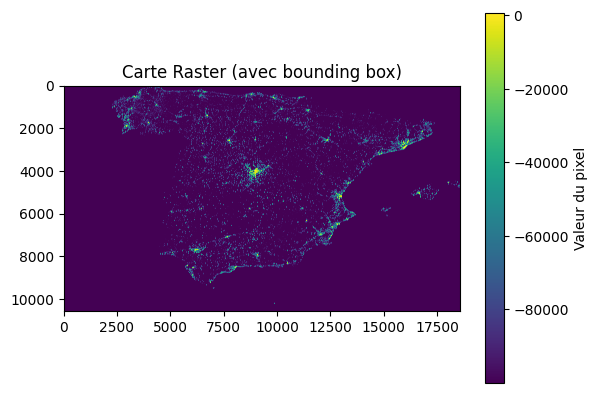

In [77]:
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rasterio.mask import mask
from rasterio.windows import from_bounds

# Définir la BoundingBox (tes coordonnées)
bounds2 = (-11.162083246, 35, 4.328749996999999, 43.792083359)

# Lire le fichier .tif
file_path = 'esp_ppp_2020_UNadj_constrained.tif'  # Remplace avec ton chemin
with rasterio.open(file_path) as src:
    # Calculer la fenêtre de la bounding box
    window = from_bounds(*bounds2, transform=src.transform)
    
    # Lire la partie du raster dans la fenêtre donnée
    raster_restrict = src.read(1, window=window)  # Lit la première couche (band)
    bounds = src.bounds
    # Afficher le raster
    plt.imshow(raster_restrict, cmap='viridis')
    plt.title("Carte Raster (avec bounding box)")
    plt.colorbar(label="Valeur du pixel")
    plt.show()


In [78]:

# 6. Convertir en coordonnées géographiques (longitude, latitude)
with rasterio.open(file_path) as src:
    raster = src.read(1)  # Lit la première couche (band)
    profile = src.profile  # Métadonnées (projection, résolution, etc.)
    bounds = src.bounds
    transform = src.transform

# 1. Aplatir le raster en un vecteur
flat_raster = raster.flatten()

# 2. Nettoyer : remplacer valeurs invalides ou négatives par 0
flat_raster[flat_raster < 0] = 0
total_pop = flat_raster.sum()
if total_pop == 0:
    raise ValueError("La population totale est nulle après nettoyage. Vérifie le raster.")

# 3. Probabilités d’échantillonnage
probs = flat_raster / total_pop

# 4. Échantillonnage d’indices
indices = np.random.choice(len(flat_raster), size=100, replace=True, p=probs)

# 5. Convertir indices en lignes / colonnes de la grille
rows, cols = np.unravel_index(indices, raster.shape)


lons, lats = rasterio.transform.xy(transform, rows, cols)

# 7. Construire un DataFrame
df = pd.DataFrame({'longitude': lons, 'latitude': lats})

df.head(5)

,longitude,latitude
0,-1.654167,40.548333
1,-0.386667,39.421667
2,-4.059167,43.355000
3,-4.260833,40.918333
4,-6.180833,37.965000


J'exclus les Canaries parce que dans mes données sur les centrales, il n'y a pas de centrale aux Canaries, et leur système de production d'électricité est complètement autonome

In [79]:
bounds2 = (-11.162083246, 35, 4.328749996999999, 43.792083359)

bounds_plot = dict(
	left=bounds2[0],
	right=bounds2[2],
	bottom=bounds2[1],
	top=bounds2[3]
	)
bounds_plot


{'left': -11.162083246,
 'right': 4.328749996999999,
 'bottom': 35,
 'top': 43.792083359}

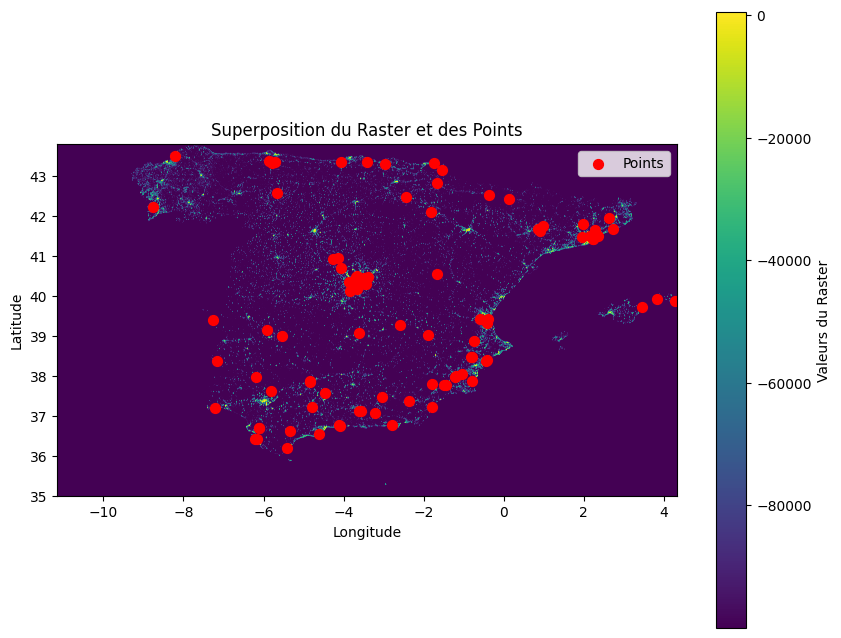

In [80]:
import geopandas as gpd
from shapely.geometry import Point
# Convertir le dataframe de points en GeoDataFrame
geometry = [Point(lon, lat) for lon, lat in zip(df['longitude'], df['latitude'])]
gdf_points = gpd.GeoDataFrame(df, geometry=geometry)

# Ploter le raster
plt.figure(figsize=(10, 8))
plt.imshow(raster_restrict, cmap='viridis', origin='upper', extent=[bounds_plot['left'], bounds_plot['right'],  bounds_plot['bottom'], bounds_plot['top']])

# Ajouter les points
gdf_points.plot(ax=plt.gca(), color='red', markersize=50, label='Points', marker='o')

# Ajouter une barre de couleur pour le raster
plt.colorbar(label='Valeurs du Raster')

# Ajouter des labels et un titre
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Superposition du Raster et des Points')

# Afficher la légende
plt.legend()

# Afficher le graphique
plt.show()

Observer le spatial mismatch

In [82]:
os.chdir("C:\\Users\\DBT3KD\\Desktop\\Etude_macro_elec\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
df.to_csv("sample_pop_dots.csv", index=False)

In [83]:
plants = pd.read_csv("plants.csv")
plants.head(5)

,plant_name,plant_url,source,wikidata,power,latitude,longitude
0,Central nuclear d'Ascó,https://openinframap.org/stats/area/Spain/plan...,nuclear,Q1640098,"1,988 MW",41.200000,0.569444
1,Central nuclear de Almaraz,https://openinframap.org/stats/area/Spain/plan...,nuclear,Q1431041,"1,957 MW",39.808056,-5.696944
2,Central Tèrmica de Cicle Combinat Sant Adrià d...,https://openinframap.org/stats/area/Spain/plan...,gas,Q5760767,"1,671 MW",41.419439,2.229719
3,Central Térmica de Castellón,https://openinframap.org/stats/area/Spain/plan...,gas,Q3434722,"1,621 MW",39.955833,0.001389
4,Central térmica de Arcos,https://openinframap.org/stats/area/Spain/plan...,gas,Q5760857,"1,585 MW",36.672500,-5.816111


C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_11804\3889286574.py:30: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = mpl.cm.get_cmap("viridis", len(df_filtered_test['source'].unique()))
C:\Users\DBT3KD\AppData\Local\Temp\ipykernel_11804\3889286574.py:60: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


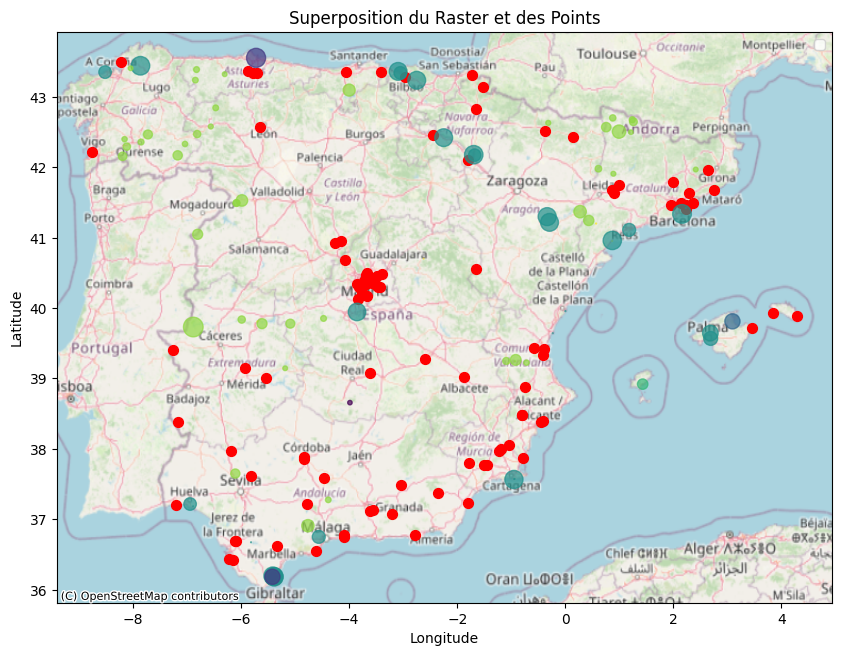

In [90]:
import geopandas as gpd
from shapely.geometry import Point
import contextily as ctx
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

# Supprimer les lignes sans coordonnées
# Supprimer les lignes sans coordonnées
df_filtered_test = plants.iloc[0:100].dropna(subset=['latitude', 'longitude'])

df_filtered_test['power_mw'] = (
    df_filtered_test['power']
    .str.replace('\xa0', '', regex=False)    # retire l'espace insécable
    .str.replace('MW', '', regex=False)      # retire "MW"
    .str.replace(',', '.', regex=False)      # remplace la virgule par un point
    .str.strip()                             # retire les espaces
    .astype(float)                           # convertit en float
)
# Créer la géométrie
geometry = [Point(xy) for xy in zip(df_filtered_test['longitude'], df_filtered_test['latitude'])]

# Créer un GeoDataFrame
plants_points = gpd.GeoDataFrame(df_filtered_test, geometry=geometry, crs="EPSG:4326")

# Reprojeter en Web Mercator
#plants_points = plants_points.to_crs(epsg=3857)

# Créer un colormap basé sur la colonne 'source'
colormap = mpl.cm.get_cmap("viridis", len(df_filtered_test['source'].unique()))

# Créer les tailles de points proportionnelles à 'output'
sizes = plants_points['power_mw'].fillna(0)
sizes = np.clip(sizes, a_min=1, a_max=None)  # Pour éviter les points invisibles
sizes_scaled = sizes / sizes.max() * 200  # Échelle à ajuster selon le rendu souhaité

# Tracer la carte
fig, ax = plt.subplots(figsize=(10, 10))

# Ajouter les points
gdf_points.plot(ax=plt.gca(), color='red', markersize=50, marker='o')
#ajouter les centrales
plants_points.plot(
    ax=ax,
    alpha=0.7,
    column='source',
    cmap=colormap,
    markersize=sizes_scaled,
    legend=True
)
# Ajouter le fond de carte
ctx.add_basemap(ax, crs=plants_points.crs.to_string(), source=ctx.providers.OpenStreetMap.Mapnik)

# Ajouter des labels et un titre
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Superposition du Raster et des Points')

# Afficher la légende
plt.legend()

# Afficher le graphique
plt.show()





In [91]:
os.chdir("C:\\Users\\DBT3KD\\Desktop\\Etude_macro_elec\\prix_electricite_gitlab\\day_ahead\\daily_temp\\outputs")
df_filtered_test.to_csv("plants_power.csv", index=False)